# Stage— Labeling

Drives Stage 3 (`subsec:stage3_labeling`) against the trajectory artifacts of one experiment:

1. queries the judge (`gpt-4o-mini`) through the locked prompt template — resumable, raw responses archived verbatim;
2. shows the label distribution;
3. creates the 60-sample human-labelling CSV and, once you fill it in, runs the Cohen's κ check (`κ ≥ 0.6`, Landis & Koch 1977).

**Requires** `OPENAI_API_KEY` in the environment. Labels are stored separately from trajectories, so relabelling never touches the GPU stages.

## Human-labelled subset (κ check)


In [10]:
# ── Celda 0: dependencias y rutas ──────────────────────────
import json, numpy as np, pandas as pd
from pathlib import Path
from sklearn.metrics import cohen_kappa_score, confusion_matrix
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

EXPERIMENTS = ["e1", "e2", "e3"]
RESULTS_DIR = Path("/home/brandon/energy_llm/results")

cfgs = {
    "e1": dict(name="e1_qwen_truthfulqa",
               figures_dir=RESULTS_DIR / "e1" / "figures"),
    "e2": dict(name="e2_llama_truthfulqa",
               figures_dir=RESULTS_DIR / "e2" / "figures"),
    "e3": dict(name="e3_qwen_triviaqa",
               figures_dir=RESULTS_DIR / "e3" / "figures"),
}
NAMES = {"e1": "Qwen — TruthfulQA",
         "e2": "LLaMA — TruthfulQA",
         "e3": "Qwen — TriviaQA"}
order = EXPERIMENTS   # ["e1", "e2", "e3"]

# ── Celda 1: paleta y estilo ────────────────────────────────
PALETTE = {
    "factual" : "#3C6E8F",
    "halluc"  : "#B5544E",
    "ink"     : "#2B2B2B",
    "muted"   : "#6B6B6B",
    "grid"    : "#D6D9DC",
    "panel"   : "#F4F6F8",
}
CMAP_AGREE = LinearSegmentedColormap.from_list(
    "agree", [PALETTE["panel"], PALETTE["factual"]])
plt.rcParams.update({
    "font.family": "serif", "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelsize": 10, "axes.edgecolor": PALETTE["muted"],
    "axes.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "text.color": PALETTE["ink"],
    "axes.labelcolor": PALETTE["ink"],
    "xtick.color": PALETTE["muted"], "ytick.color": PALETTE["muted"],
    "figure.dpi": 150,
})

# ── Celda 2: carga de datos ─────────────────────────────────
data = {}
for exp in EXPERIMENTS:
    raw = json.loads((RESULTS_DIR / exp / "labels.json").read_text())
    values = np.array(list(raw.values()))
    data[exp] = {
        "values": values,
        "n": len(values),
        "n_supported": int((values == 0).sum()),
        "n_hall": int(values.sum()),
    }
print("Loaded:", {e: data[e]["n"] for e in EXPERIMENTS})  # debe dar 817/817/500

Loaded: {'e1': 817, 'e2': 817, 'e3': 500}


## Label distribution

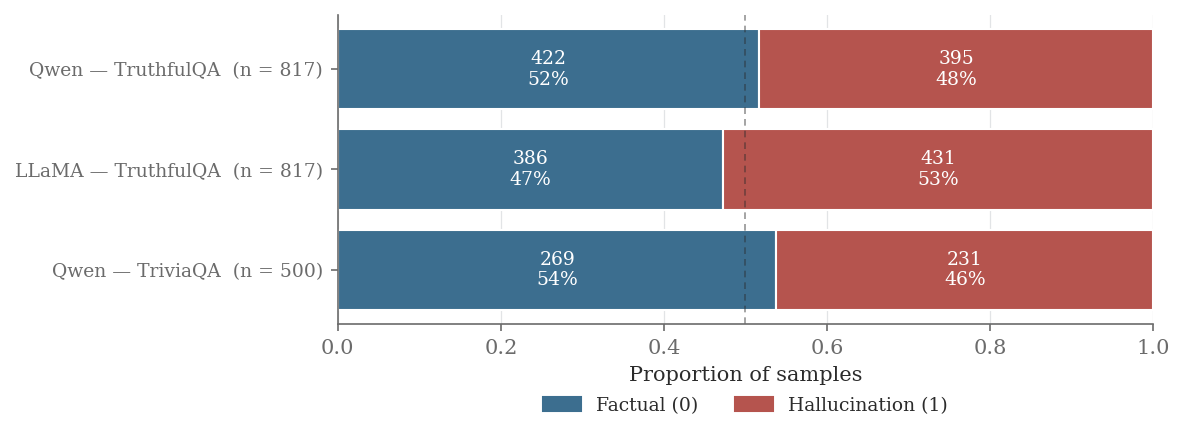

Saved.


In [14]:
LABELS = ["Factual (0)", "Hallucination (1)"]

fig, ax = plt.subplots(figsize=(8, 3.0))

for i, exp in enumerate(order):
    d = data[exp]
    p_fact = d["n_supported"] / d["n"]
    p_hall = d["n_hall"] / d["n"]

    ax.barh(i, p_fact, color=PALETTE["factual"], edgecolor="white", linewidth=1.0)
    ax.barh(i, p_hall, left=p_fact, color=PALETTE["halluc"],
            edgecolor="white", linewidth=1.0)

    ax.text(p_fact / 2, i, f"{d['n_supported']}\n{p_fact*100:.0f}%",
            ha="center", va="center", color="white", fontsize=9)
    ax.text(p_fact + p_hall / 2, i, f"{d['n_hall']}\n{p_hall*100:.0f}%",
            ha="center", va="center", color="white", fontsize=9)

ax.axvline(0.5, color=PALETTE["ink"], lw=0.8, ls=(0, (4, 3)), alpha=0.5)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(
    [f"{NAMES[e]}  (n = {data[e]['n']})" for e in order], fontsize=9)
ax.set_xlim(0, 1)
ax.set_xlabel("Proportion of samples")
ax.invert_yaxis()
ax.grid(axis="x", color=PALETTE["grid"], alpha=0.7, linestyle="-", linewidth=0.6)
ax.set_axisbelow(True)

handles = [plt.Rectangle((0,0), 1, 1, color=PALETTE["factual"]),
           plt.Rectangle((0,0), 1, 1, color=PALETTE["halluc"])]
ax.legend(handles, LABELS,
          loc="upper center",
          bbox_to_anchor=(0.5, -0.18),   # más cerca del eje
          ncol=2, frameon=False, fontsize=9)

fig.subplots_adjust(bottom=0.22)        # hace espacio abajo para leyenda + xlabel

fig.tight_layout()
for exp in order:
    Path(cfgs[exp]["figures_dir"]).mkdir(parents=True, exist_ok=True)
    fig.savefig(Path(cfgs[exp]["figures_dir"]) / "label_distribution.png",
                dpi=150, bbox_inches="tight")
plt.show()
print("Saved.")

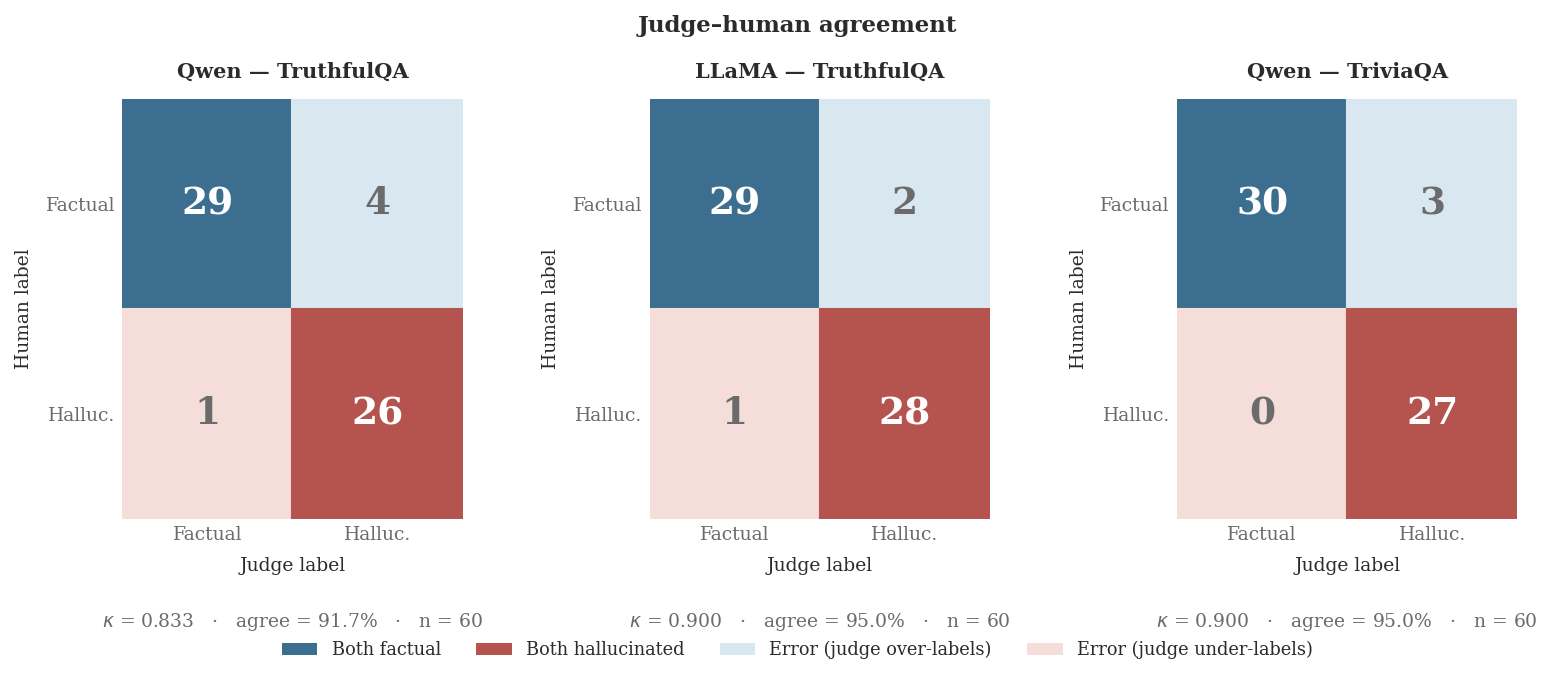

Saved. κ assertions passed.


In [16]:
# Celda 4 rediseñada — confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(12, 4.0))

# Colores por celda: diagonal=clase, off-diagonal=neutro claro
CELL_COLORS = {
    (0, 0): PALETTE["factual"],   # human=fact, judge=fact  → correcto
    (1, 1): PALETTE["halluc"],    # human=hall, judge=hall  → correcto
    (0, 1): "#D9E8F0",            # human=fact, judge=hall  → error
    (1, 0): "#F5DDD9",            # human=hall, judge=fact  → error
}
TEXT_COLORS = {
    (0, 0): "white", (1, 1): "white",
    (0, 1): PALETTE["muted"],    (1, 0): PALETTE["muted"],
}
TICK_LABELS = ["Factual", "Halluc."]

for ax, exp in zip(axes, order):
    df = pd.read_csv(RESULTS_DIR / exp / "human_labels.csv")
    df = df.dropna(subset=["human_label", "judge_label"])
    h = df["human_label"].astype(int).to_numpy()
    j = df["judge_label"].astype(int).to_numpy()

    cm    = confusion_matrix(h, j, labels=[0, 1])
    kappa = cohen_kappa_score(h, j)
    agree = np.trace(cm) / cm.sum()

    # assert against canonical values
    expected = {"e1": 0.833, "e2": 0.900, "e3": 0.900}
    assert abs(kappa - expected[exp]) < 0.001, \
        f"{exp}: κ {kappa:.3f} ≠ {expected[exp]}"

    # draw cells manually
    for r in range(2):
        for c in range(2):
            ax.add_patch(plt.Rectangle(
                (c - 0.5, r - 0.5), 1, 1,
                color=CELL_COLORS[(r, c)], zorder=0))
            ax.text(c, r, str(cm[r, c]),
                    ha="center", va="center",
                    fontsize=18, fontweight="bold",
                    color=TEXT_COLORS[(r, c)], zorder=1)

    ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
    ax.set_xticks([0, 1]); ax.set_xticklabels(TICK_LABELS, fontsize=9)
    ax.set_yticks([0, 1]); ax.set_yticklabels(TICK_LABELS, fontsize=9)
    ax.set_xlabel("Judge label", fontsize=9, labelpad=6)
    ax.set_ylabel("Human label", fontsize=9, labelpad=6)
    ax.invert_yaxis()
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(length=0)

    # título limpio: nombre del experimento
    ax.set_title(NAMES[exp], fontsize=10, fontweight="bold", pad=10)

    # stats como anotación compacta debajo del panel
    ax.text(0.5, -0.22,
            f"$\\kappa$ = {kappa:.3f}   ·   agree = {agree*100:.1f}%   ·   n = {len(df)}",
            transform=ax.transAxes, ha="center", va="top",
            fontsize=9, color=PALETTE["muted"])

# leyenda de colores de celda
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=PALETTE["factual"], label="Both factual"),
    Patch(facecolor=PALETTE["halluc"],  label="Both hallucinated"),
    Patch(facecolor="#D9E8F0",          label="Error (judge over-labels)"),
    Patch(facecolor="#F5DDD9",          label="Error (judge under-labels)"),
]
fig.legend(handles=legend_elements, loc="lower center",
           bbox_to_anchor=(0.5, -0.08), ncol=4,
           frameon=False, fontsize=8.5)

fig.suptitle("Judge–human agreement",
             fontsize=11, fontweight="bold", y=1.02)
fig.subplots_adjust(wspace=0.55, bottom=0.18)

for exp in order:
    fig.savefig(Path(cfgs[exp]["figures_dir"]) / "judge_human_agreement.png",
                dpi=150, bbox_inches="tight")
plt.show()
print("Saved. κ assertions passed.")